[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Jordy-Castillo/FC_Jordy-Castillo-Trabajos/blob/main/Taller07/FC_Taller07_JordyCastillo.ipynb)

# **FISICA COMPUTACIONAL - TALLER #7**
* **Tema:** Arreglos: integración y derivación numérica
* **Lenguaje:** Fortran & Python
* **Estudiante:** Jordy Castillo Jordán
* **Fecha:** 05/11/2026



In [1]:
!which gfortran || (apt-get update -qq && apt-get install -y gfortran)
!gfortran --version | head -n 1
!mkdir -p taller_oscilador_romberg

/usr/bin/gfortran
GNU Fortran (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0



---
# **PARTE A:**
Un sensor registra la posición de un oscilador amortiguado:

$$x(t) = e^{-\gamma t}\cos(\omega t),$$

donde $x$ es la posición [m] (amplitud inicial 1 m), $t$ el tiempo [s], $\gamma = 0.5\ \text{s}^{-1}$ el coeficiente de amortiguamiento, que fija la rapidez con que decae la amplitud, y $\omega = 2\pi\ \text{rad/s}$ la frecuencia angular de oscilación (periodo de 1 s). Esta posición es solución de la ecuación del oscilador amortiguado

$$\ddot{x} + 2\gamma\,\dot{x} + \omega_0^2\,x = 0, \qquad \omega_0^2 = \omega^2 + \gamma^2,$$

donde $2\gamma\dot{x}$ es la fuerza de fricción por unidad de masa, proporcional a la velocidad, y $\omega_0$ es la frecuencia natural del oscilador sin amortiguamiento. La velocidad y la aceleración exactas son

$$v(t) = -e^{-\gamma t}\left[\gamma\cos(\omega t) + \omega\sin(\omega t)\right], \qquad a(t) = e^{-\gamma t}\left[(\gamma^2 - \omega^2)\cos(\omega t) + 2\gamma\omega\sin(\omega t)\right].$$

**Energía disipada.** La energía mecánica por unidad de masa [J/kg] es

$$E(t) = \underbrace{\tfrac{1}{2}v^2}_{\text{cinética}} + \underbrace{\tfrac{1}{2}\omega_0^2 x^2}_{\text{potencial elástica}} .$$

Derivando y usando la ecuación del oscilador se obtiene $\frac{dE}{dt} = -2\gamma v^2$: la fricción extrae energía a un ritmo $2\gamma v^2$. Integrando entre $0$ y $T$,

$$E_{\text{dis}} = \int_0^T 2\gamma\,v(t)^2\,dt = E(0) - E(T),$$

donde $E_{\text{dis}}$ es la energía disipada por la fricción en el intervalo $[0, T]$. El lado derecho se calcula directamente con $x$ y $v$ en los dos extremos; el lado izquierdo requiere una integral numérica. Que coincidan es una prueba de la conservación de la energía.

**El taller tiene tres partes:**

| Parte | Lenguaje | Qué se hace |
|---|---|---|
| B | Fortran | Módulo de integración de Romberg; energía disipada en $T = 3$ s |
| C | Python | Velocidad y aceleración a partir de las posiciones, con varias fórmulas, comparadas con las exactas |
| D | Fortran | El mismo módulo de Romberg aplicado a $\pi = \int_0^1 \frac{4}{1+x^2}\,dx$, comparado con Monte Carlo (Taller 5) |

**Requisitos generales**

1. Todo el trabajo se guarda en una carpeta llamada `taller_oscilador_romberg`, con los nombres de archivo que se indican en cada parte.
2. Se usa doble precisión: `real(dp)` en Fortran y `float` (64 bits) en Python.
3. La tabla de Romberg se almacena en un arreglo `allocatable` de dos dimensiones con índices desde 0.
4. Las derivadas se calculan sobre el arreglo completo con rebanadas, sin ciclos `for` sobre los puntos.
5. Se entrega el pseudocódigo marco de la Parte B con sus tres espacios completos.


<div style="border-left: 5px solid #B02A20; background-color: #FBEDEC; padding: 10px 14px; margin: 8px 0;">

**No está permitido** usar `np.gradient`, `np.trapz`, `np.trapezoid`, `scipy.integrate` ni ninguna función de biblioteca que integre o derive. Las fórmulas se programan a partir de las secciones 3 y 4. Cada estudiante sustentará su programa.

</div>


---
# **PARTE B:**
**Actividades**

1. Complete el pseudocódigo marco. Los tres espacios se deducen de la sección 3.4 y de su nota sobre el refinamiento del trapecio.
2. Escriba el módulo `modulo_romberg.f90` con la integración de Romberg y los integrandos, y el programa `programa_energia.f90` que lo usa. La organización en procedimientos es decisión suya; debe respetar las reglas de la Semana 6 (`intent` en todos los argumentos, procedimientos en el módulo). El mismo módulo se usará sin cambios en la Parte D.
3. Calcule $E_{\text{dis}}$ en $[0, 3]$ s con tolerancia $10^{-6}$ y el criterio de parada de la diagonal, contando las evaluaciones del integrando.
4. Calcule $E(0) - E(T)$ con las fórmulas de $x$ y $v$, y compárelo con $E_{\text{dis}}$.
5. Escriba la tabla en `tabla_energia.dat` y el resultado en `resultado_energia.dat`. Compile con `-fcheck=bounds`.

**Qué preparar**

| Archivo | Contenido |
|---|---|
| `modulo_romberg.f90` | Integración de Romberg con conteo de evaluaciones; integrandos $2\gamma v^2$ (Parte B) y $4/(1+x^2)$ (Parte D) |
| `programa_energia.f90` | Usa el módulo; escribe los dos archivos `.dat` de esta parte |
| `tabla_energia.dat` | Una fila por nivel $k = 0, \dots, k_{\text{final}}$, con $S_{k,0}, \dots, S_{k,k}$ |
| `resultado_energia.dat` | Una línea: $k_{\text{final}}$, número de evaluaciones, $E_{\text{dis}}$ (Romberg), $E(0) - E(T)$, diferencia absoluta |

<div style="border-left: 5px solid #2E7D32; background-color: #EAF5EA; padding: 10px 14px; margin: 8px 0;">

**Consejo.** Pasar una función como argumento de otra requiere bloques `interface`, que se ven en el Capítulo 4. Por ahora, el módulo puede contener los dos integrandos y una función que elija entre ellos según un argumento entero; así la integración de Romberg se escribe una sola vez y sirve para las Partes B y D.

</div>

<div style="border-left: 5px solid #2E7D32; background-color: #EAF5EA; padding: 10px 14px; margin: 8px 0;">

**Consejo.** Cuente las evaluaciones del integrando dentro del procedimiento que lo llama, no a mano. La tabla hasta el nivel $k$ debe usar exactamente $2^k + 1$ evaluaciones; si su programa reporta más, está evaluando la función dos veces en algunos puntos: revise el espacio 1 del pseudocódigo.

</div>


### **B.1** Diseño: pseudocódigo marco


**Pseudocódigo marco de la integración de Romberg**

```
ENTRADAS: a, b, tol, kmax
h      ← b − a           (Δx: un solo subintervalo en el nivel 0)
S(0,0) ← (h/2)·[ f(a) + f(b) ]
n_eval ← 2
PARA k = 1, 2, ..., kmax:
    h ← h/2

!!! ESPACIO 1: suma de f en los puntos nuevos del nivel k !!!    
    suma ← 0
    PARA i = 1, 2, ..., 2^(k-1):
      x_nuevo ← a + (2*i - 1) * h
      suma ← suma + f(x_nuevo)
    FIN PARA

!!! ESPACIO 2: número de puntos nuevos del nivel k !!!
    puntos_nuevos ← 2^(k-1)
    n_eval ← n_eval + puntos_nuevos

    S(k,0) ← S(k−1,0)/2 + h·suma

    PARA j = 1, ..., k:

!!! ESPACIO 3: extrapolación de Richardson !!!
        S(k,j) ← ((4^j) * S(k, j-1) - S(k-1, j-1)) / ((4^j) - 1)
    FIN PARA

    SI |S(k,k) − S(k−1,k−1)| < tol:
    TERMINAR con k_final = k

FIN PARA

SALIDAS: tabla S, k_final, n_eval
```

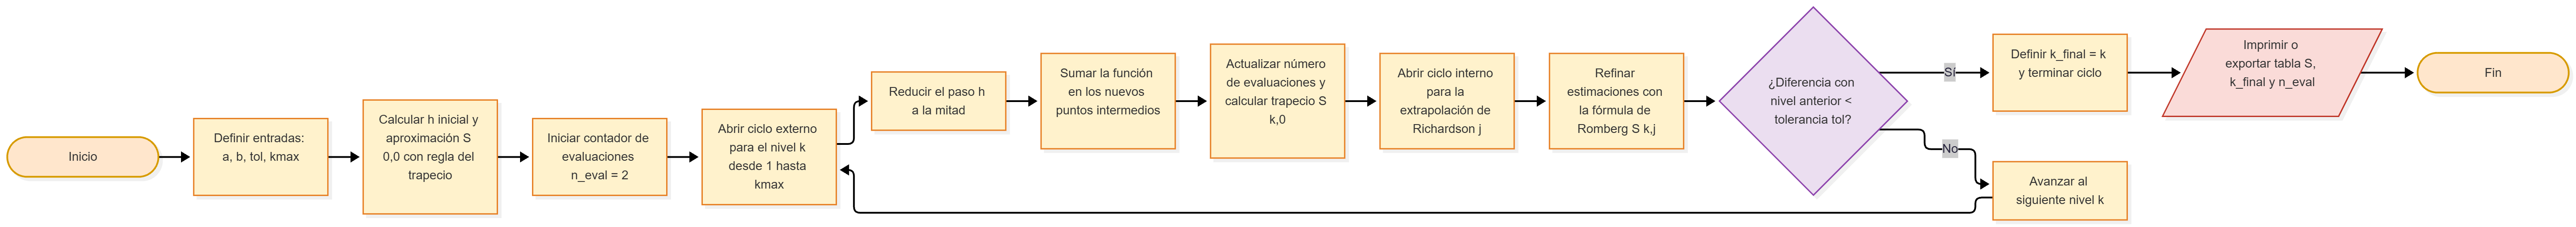

In [16]:
#ELABORACION MEDIANTE MERMAID
from IPython.display import Image
Image(filename="/content/T7_DiagramaB.png")


### **B.2 A B.5** Modulo y Programa


In [2]:
%%writefile taller_oscilador_romberg/modulo_romberg.f90
!!!!!!!!!! CONSTRUIR FUNCION DE INTEGRACION DE ROMBERG Y LOS INTEGRANDOS !!!!!!!!!!

module modulo_romberg
  implicit none
  integer, parameter :: dp = kind(1.0d0)                          !precisión

!! INTEGRAMOS LA POTENCIA DISIPADA POR FRICCION !!

contains
  real(dp) function f_energia(t)                                  ! Funcion integrando 2gamma*v(t)^2
    real(dp), intent(in) :: t                                     ! Tiempo (s)
    real(dp), parameter  :: gamma = 0.5_dp                        ! Coeficiente de amortiguamiento (s^-1)
    real(dp), parameter  :: w = 2.0_dp *4.0_dp* atan(1.0_dp)      ! Frecuencia angular de oscilación (rad/s) con PI = 4*arctan(1)
    real(dp) :: v                                                 ! Velocidad (m/s)

    v = -exp(-gamma*t) * (gamma*cos(w*t) + w*sin(w*t))            !Calculo de la Velocidad en funcion del tiempo v(t)
    f_energia = 2.0_dp * gamma * v**2                             !Calculo de la energia
  end function f_energia

!! INTEGRAMOS LA FUNCION PARA EL CALCULO PI > 4/(1+X^2) !!

  real(dp) function f_pi(x)                                       ! Funcion integrando 4/(1+x^2)
    real(dp), intent(in) :: x                                     ! Posicion
    f_pi = 4.0_dp / (1.0_dp + x**2)                               !Calculo de la funcion
  end function f_pi

!! CREAMOS UNA FUNCION QUE SELECCIONE EL INTENGRANDO !!

  real(dp) function eval_f(x, tipo_funcion)                       !funcion integrando 4/(1+x^2) --> es como un selector
    real(dp), intent(in) :: x                                     ! Posicion
    integer, intent(in) :: tipo_funcion                          ! Tipo de funcion (energia o de pi)

    if (tipo_funcion == 1) then                                   !Si el tipo de funcion es 1 llama al integrando 2gamma*v(t)^2
      eval_f = f_energia(x)
    else if (tipo_funcion == 2) then                              !Si el tipo de funcion es 2 llama al integrando 4/(1+x^2)
      eval_f = f_pi(x)
    else
      eval_f = 0.0_dp                                             !Si el tipo de funcion no es valido devuelve 0
    end if
  end function eval_f

!! SUBRUTINA PARA LA INTEGRACION DE ROMBERG !!

  subroutine integrar_romberg(a, b, tol, kmax, tipo_funcion, S, k_final, n_eval)
    real(dp), intent(in)  :: a, b, tol                            !Rango de integracion (a y b), tolerancia
    integer, intent(in)   :: kmax, tipo_funcion                    !Numero de niveles y tipo de funcion
    real(dp), intent(out) :: s(0:, 0:)                            !Arreglo de resultados
    integer, intent(out)  :: k_final, n_eval                      !Nivel final y numero de evaluaciones
    integer  :: k, j, i, puntos_nuevos                             !Variables para el bucle
    real(dp) :: h, suma, x_nuevo                                  !Variables para el bucle

    !INICIAR EL NIVEL K = 0
    h = b - a
    s(0,0) = 0.5_dp * h * (eval_f(a, tipo_funcion) + eval_f(b, tipo_funcion))    !regla del trapecio cuando K=0
    n_eval = 2                                                                   !inicia un contador en 2 evaluaciones (f(a) y f(b))
    k_final = kmax                                                               !inicia el nivel maximo en el nivel maximo

    !BUCLE PARA EL NIVEL K = 1, 2, ..., KMAX
    do k = 1, kmax                                                               !realiza los refinamientos de la malla
      h = h/2.0_dp                                                               !se reduce el ancho del intervalo
      suma = 0.0_dp                                                              !se reinicia la suma
      puntos_nuevos = 2**(k-1)                                                   !se calcula el numero de puntos nuevos en el nivel k

      do i = 1, puntos_nuevos
        x_nuevo = a + real(2*i-1, dp) * h                                        !puntos medios impares del intervalo
        suma = suma + eval_f(x_nuevo, tipo_funcion)                              !se suma la funcion en los puntos medios impares
      end do

      n_eval = n_eval + puntos_nuevos                                            !incrementa el contador de evaluaciones
      S(k,0) = 0.5_dp * S(k-1,0) + h * suma                                      !aplicar formula de refinamiento del trapecio

      do j = 1, k
        S(k,j) = ((4.0_dp**j) * S(k, j-1) - S(k-1, j-1)) / ((4.0_dp**j) - 1.0_dp)  !extrapolacion de richardson para las columnas superiores
      end do

      if (abs(S(k,k) - S(k-1, k-1)) < tol ) then                                 !criterio de parada
        k_final = k                                                              !se actualiza el nivel final
        exit                                                                     !salir del bucle
      end if
    end do
  end subroutine integrar_romberg
end module modulo_romberg

Overwriting taller_oscilador_romberg/modulo_romberg.f90


In [3]:
%%writefile taller_oscilador_romberg/programa_energia.f90
!!!!!!!!!! CALCULAR ENERGIA DISIPADA EN UN OSCILADOR AMORTIGUADO !!!!!!!!!!

program programa_energia
  use modulo_romberg, only : dp, integrar_romberg
  implicit none

  real(dp), parameter :: gamma = 0.5_dp                             ! Coeficiente de amortiguamiento (s^-1)
  real(dp), parameter :: w = 2.0_dp * 4.0_dp * atan(1.0_dp)         ! Frecuencia angular
  real(dp), parameter :: w0_sq = w**2 + gamma**2                    ! Frecuencia natural al cuadrado
  real(dp), parameter :: a = 0.0_dp                                 ! Tiempo inicial (s)
  real(dp), parameter :: b = 3.0_dp                                 ! Tiempo final (s)
  real(dp), parameter :: tol = 1.0e-6_dp                            ! Tolerancia corregida
  integer, parameter :: kmax = 12                                   ! nivel maximo
  real(dp), allocatable :: S(:,:)                                   ! Arreglo de resultados
  integer  :: k_final, n_eval, k, j                                 ! Variables para el bucle
  real(dp) :: e_dis, e_0, e_T, e_ref, diferencia                    ! Variables para el bucle

  allocate(S(0:kmax, 0:kmax))                                       ! Reservar memoria para el arreglo

!! CALCULO DE E_DIS Y COMPARACION CON E_0-E_T DE B.3 Y B.4!!

  call integrar_romberg(a, b, tol, kmax, 1, S, k_final, n_eval)     !llamamos a la funcion integrar_romberg para calcular la energia disipada
  e_dis = S(k_final, k_final)                                       !Energia disipada de la punta diagonal principal
  e_0 = 0.5_dp * ((-gamma)**2) + 0.5_dp * w0_sq * (1.0_dp**2)       !Energia del oscilador al tiempo inicial, t=0 : x(0)= 1.0 and v(0) = -gamma
  e_T = calcular_energia_exacta(b, gamma, w, w0_sq)                 !Energia del oscilador al tiempo final

  e_ref = e_0 - e_T                                                 ! Energia exacta
  diferencia = abs(e_dis - e_ref)                                   ! Diferencia de energia exacta

!! ELABORACION DE TABLA_ENERGIA.DAT DE B.5!!

  open(unit = 10, file = "tabla_energia.dat", status = "replace", action = "write")
  do k = 0, k_final
    write(10, "(I3)", advance = "NO") k
    do j = 0, k
      write(10, "(1X, ES25.15)", advance = "NO") S(k,j)             !advance="NO" permite escribir varios numeros en la misma fila (NUEVO)
    end do
    write(10, *)
  end do
  close(10)

!! ESCRIBIR ARCHIVO RESULTADO_ENERGIA.DAT !!

  open(unit=20, file="resultado_energia.dat", status="replace", action="write")
  write(20, "(I5, 1X, I10, 1X, ES25.15, 1X, ES25.15, 1X, ES25.15)") k_final, n_eval, e_dis, e_ref, diferencia
  close(20)

  deallocate(S)                                                          !Liberar memoria del arreglo

contains
  real(dp) function calcular_energia_exacta(t, gamma, w, w0_sq)          !funcion para la energia exacta en un tiempo = t
    real(dp), intent(in) :: t, gamma, w, w0_sq                           !Variables de entrada
    real(dp) :: xt, vt                                                   !variables para la energia exacta
    xt = exp(-gamma*t) * cos(w*t)                                        !calcular la posicion exacta con la ecuacion
    vt = -exp(-gamma*t) * (gamma*cos(w*t) + w*sin(w*t))                  !calcular la velocidad exacta con la ecuacion
    calcular_energia_exacta = 0.5_dp * vt**2 + 0.5_dp * w0_sq * xt**2    !calcular la energia exacta

  end function calcular_energia_exacta

end program programa_energia

Overwriting taller_oscilador_romberg/programa_energia.f90


In [4]:
# Compilar y ejecutar la Parte B
!cd taller_oscilador_romberg && gfortran -fcheck=bounds -o programa_energia modulo_romberg.f90 programa_energia.f90 && ./programa_energia


---
# **PARTE C:**
**Actividades**

1. Escriba `derivadas_oscilador.py`. Construya el arreglo de tiempos en $[0, 3]$ s con paso $\Delta t$ y el arreglo de posiciones $x(t)$.
2. Obtenga la velocidad con las cuatro fórmulas de la sección 4.1 (adelantada, atrasada, central y cinco puntos) y la aceleración con la fórmula central de la sección 4.2. Cada fórmula se evalúa solo en los puntos donde está definida: por ejemplo, la central no existe en el primer ni en el último punto.
3. Con $\Delta t = 0.01$ s, escriba `derivadas_oscilador.dat` con cuatro columnas ($t$, $x$, $v$ central, $a$ central) en los puntos donde la fórmula central está definida, y grafique $v$ y $a$ numéricas junto con las exactas en `derivadas_oscilador.png`.
4. Para $\Delta t = 0.01$ s y $\Delta t = 0.005$ s, obtenga el error máximo de cada fórmula frente a la derivada exacta. Escriba `errores_derivadas.dat` con dos filas y seis columnas: $\Delta t$, error de la adelantada, de la atrasada, de la central y de cinco puntos para $v$, y error de la central para $a$.
5. Obtenga la razón entre los errores de los dos pasos para cada fórmula y compárela con la tabla de la sección 4.2.

**Qué preparar**

| Archivo | Contenido |
|---|---|
| `derivadas_oscilador.py` | Construye los datos, deriva con rebanadas, escribe los archivos y la figura |
| `derivadas_oscilador.dat` | $\Delta t = 0.01$ s: $t$, $x$, $v$, $a$ en los 299 puntos interiores |
| `errores_derivadas.dat` | Dos filas ($\Delta t = 0.01, 0.005$): $\Delta t$ y los cinco errores máximos |
| `derivadas_oscilador.png` | $v$ y $a$ numéricas y exactas contra $t$ |

In [5]:
%%writefile taller_oscilador_romberg/derivadas_oscilador.py

import numpy as np
import matplotlib.pyplot as plt

### PARAMETROS DEL OSCILADOR ###

gamma = 0.5                   #coeficiente de amortiguamiento (s^-1)
w = 2*np.pi                   #frecuencia angular (rad/s)
w0_sq = w**2 + gamma**2

### DEFINICION DE FUNCIONES DE REFERENCIA DE x, v, a SEGUN LAS ECUACIONES ###

def x_ex(t):
  return np.exp(-gamma*t) * np.cos(w*t)

def v_ex(t):
  return -np.exp(-gamma*t) * (gamma*np.cos(w*t) + w*np.sin(w*t))

def a_ex(t):
  return np.exp(-gamma*t) * ((gamma**2 - w**2) * np.cos(w*t) + 2*gamma*w*np.sin(w*t))

### FUNCION PARA CALCULAR DERIVADAS Y ERRORES SEGUN EL dt ###

def procesar_malla(dt):
  N = int(round(3.0 / dt))              #calcular numero de pasos en 3 segundos, con redondeo al entero mas cercano
  t = np.linspace(0.0, 3.0, N+1)        #arreglo de tiempo N+1 puntos para 0.01s
  x = x_ex(t)                           #posición exacta del arreglo

  ## VELOCIDADES CON 4 FORMULAS DE C.2 ##
  v_adelantada = (x[1:] - x[:-1]) / dt                                          #rebanadas segun la tabla del codigo de teoria dado
  v_atrasada   = (x[1:] - x[:-1]) / dt
  v_central    = (x[2:] - x[:-2]) / (dt *2.0)
  v_cinco_puntos = (-x[4:] + 8.0*x[3:-1] - 8.0*x[1:-3] + x[:-4]) / (12.0*dt)

  ## ACELERACION CON 1 FORMULA DE C.2 ##
  a_central = (x[2:] - 2.0*x[1:-1] + x[:-2]) / (dt**2)

  ## ERRORES MAXIMOS ABSOLUTOS ##
  error_v_adelantada   = np.max(np.abs(v_adelantada   - v_ex(t[:-1])))        #formula del error absoluto
  error_v_atrasada     = np.max(np.abs(v_atrasada     - v_ex(t[1:])))
  error_v_central      = np.max(np.abs(v_central      - v_ex(t[1:-1])))
  error_v_cinco_puntos = np.max(np.abs(v_cinco_puntos - v_ex(t[2:-2])))
  error_a_central      = np.max(np.abs(a_central      - a_ex(t[1:-1])))

  error_fila = [dt, error_v_adelantada, error_v_atrasada, error_v_central, error_v_cinco_puntos, error_a_central]
  return t, x, v_adelantada, v_atrasada, v_central, v_cinco_puntos, a_central, error_fila

### PROCESO PARA dt = 0.01s de C.3  ###

dt_1 = 0.01
t1, x1, v_ad1, v_at1, v_cent1, v_5p1, a_cent1, error1 = procesar_malla(dt_1)

## guardar en derivadas_oscilador.dat con los 299 puntos
t_int = t1[1:-1]
x_int = x1[1:-1]
datos_salida1 = np.column_stack((t_int, x_int, v_cent1, a_cent1))
np.savetxt("derivadas_oscilador.dat", datos_salida1, fmt="%25.15e")

## generamos la grafica comparativa de derivadas_oscilador.png ##

plt.figure(figsize=(10, 6))
plt.subplot(2,1,1)
plt.plot(t_int, v_ex(t_int), '-', label="v exacta", color="red", linewidth=1.5)
plt.plot(t_int, v_cent1, '--', label="v central numerica.", color="blue", linewidth=1.2)
plt.ylabel("Velocidad [m/s]")
plt.title("Velocidad y Aceleración del Oscilador Amortiguado (dt = 0.01 s)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(2, 1, 2)
plt.plot(t_int, a_ex(t_int), '-', label="a exacta", color="orange", linewidth=1.5)
plt.plot(t_int, a_cent1, '--', label="a central numerica.", color="purple", linewidth=1.2)
plt.xlabel("Tiempo [s]")
plt.ylabel("Aceleración [m/s^2]")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("derivadas_oscilador.png", dpi=250)
plt.close()

### PROCESO PARA dt = 0.005s de C.4  ###

dt_2 = 0.005
t2, x2, v_ad2, v_at2, v_cent2, v_5p2, a_cent2, error2 = procesar_malla(dt_2)
matriz_errores = np.array([error1, error2])
np.savetxt("errores_derivadas.dat", matriz_errores, fmt="%25.15e")

print("Parte C ejecutada y archivos generados")

Overwriting taller_oscilador_romberg/derivadas_oscilador.py


In [6]:
# Ejecutar la Parte C dentro de la carpeta del taller
!cd taller_oscilador_romberg && python derivadas_oscilador.py

Parte C ejecutada y archivos generados



---
# **PARTE D:**

**Actividades**

1. Escriba `programa_pi.f90`, que use `modulo_romberg.f90` **sin modificarlo** para calcular $\pi = \int_0^1 \frac{4}{1+x^2}\,dx$ con tolerancia $10^{-5}$.
2. Escriba en `resultado_pi.dat` una línea con $k_{\text{final}}$, el número de evaluaciones, el valor obtenido y su error $|S_{k,k} - \pi|$.
3. Con el programa de Monte Carlo de su Taller 5, estime $\pi$ con $N = 10^6$ muestras y anote el error.
4. Con el error estadístico $\sigma/\sqrt{N}$ de Monte Carlo, donde $\sigma = 4\sqrt{p(1-p)}$ y $p = \pi/4$, obtenga cuántas muestras harían falta para un error de $10^{-5}$.
5. Resuma en el reporte una tabla con tres filas (Romberg; Monte Carlo con $10^6$ muestras; Monte Carlo con error $10^{-5}$) y dos columnas (evaluaciones, error).

**Qué preparar**

| Archivo | Contenido |
|---|---|
| `programa_pi.f90` | Usa `modulo_romberg.f90` sin cambios; escribe `resultado_pi.dat` |
| `resultado_pi.dat` | Una línea: $k_{\text{final}}$, evaluaciones, valor de $\pi$, error |


### **D.1** Programa y resultado


In [7]:
%%writefile taller_oscilador_romberg/programa_pi.f90

program programa_pi
  use modulo_romberg, only: dp, integrar_romberg
  implicit none

  real(dp), parameter :: a = 0.0_dp                !Rango de integracion inferior
  real(dp), parameter :: b = 1.0_dp                !Rango de integracion superior
  real(dp), parameter :: tol = 1.0e-5_dp           !Tolerancia
  integer, parameter :: kmax = 10                  !nivel maximo
  real(dp) :: pi_exacto, pi_numerico, error_pi     !Variables para el calculo de pi
  integer :: k_final, n_eval                       !Variables para el bucle
  real(dp), allocatable :: S(:,:)                  !Arreglo de resultados

  allocate(S(0:kmax, 0:kmax))                                       !Reservar memoria para el arreglo
  call integrar_romberg(a, b, tol, kmax, 2, S, k_final, n_eval)     !llamar a la funcion integrar_romberg para calcular

!! CALCULO DEL VALOR NUMERICO Y DEL ERROR !!
  pi_exacto = 4.0_dp*atan(1.0_dp)
  pi_numerico = S(k_final, k_final)
  error_pi = abs(pi_numerico - pi_exacto)

!! ESCRIBIR ARCHIVO RESULTADO_PI.DAT DE D.2 !!
  open(unit=10, file="resultado_pi.dat", status="replace", action="write")
  write(10, "(I5, 1X, I10, 1X, ES25.15, 1X, ES25.15)") k_final, n_eval, pi_numerico, error_pi
  close(10)

  deallocate(S)                                                     !Liberar memoria del arreglo

end program programa_pi

Overwriting taller_oscilador_romberg/programa_pi.f90


In [8]:
# Compilar y ejecutar la Parte D dentro de la carpeta del taller
!cd taller_oscilador_romberg && gfortran -fcheck=bounds -o programa_pi modulo_romberg.f90 programa_pi.f90 && ./programa_pi


### **D.3** Monte Carlo


**IMAGEN EXTRAIDA DEL CODIGO DEL TALLER 5**

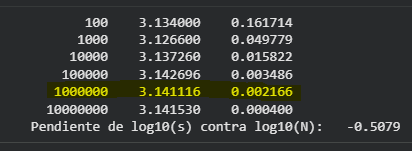

Al utilizar el metodo de Monte Carlo del Taller 5 para una estimación de $\pi$ de $N = 10^{6}$, se puede evidenciar que el valor estimado es  $\pi = 3.141116$ con una desviación estandar muestral ($s$) de 0.002166, y un error absoluto de $4,767×10^{-4}$, es decir, de un orden de $10^{-4}$. De igual forma, su E.R.P fue de $0.015\%$.




### **D.4** ¿cuántas muestras harían falta para un error de $10^{-5}$?


Al usar la ecuación del error dada en el enunciado, podemos despejar la cantidad de muestras $(N)$ de la ecuación para poder determinarlas. Teniendo en cuenta que el error es $10^{-5}$, el cual es el deseado.
\
\
$$\text{Error} = \frac{\sigma}{\sqrt{N}}  \quad--> \quad N = \left(\frac{\sigma}{\text{Error}}\right)^2 \quad--> \quad N = \left(\frac{4\sqrt{p(1-p)}}{\text{Error}}\right)^2$$


In [9]:
import numpy as np

p = np.pi / 4                      #definimos el valor de (p) dado por el enunciado
numerador = 4* np.sqrt(p*(1-p))    #definimos el numerador para evitar fallos de sintaxis
error = 10**-5                     #definimos el numerador
N = (numerador/error)**2           #definimos la ecuación general

print("La cantidad de muestras que harian falta para un error de 10^{-5} son: ", N)

La cantidad de muestras que harian falta para un error de 10^{-5} son:  26967662132.698143



---
# **PARTE E:**



1. **Conservación de la energía.** ¿Qué tan cerca están $E_{\text{dis}}$ y $E(0) - E(T)$? Compare esa diferencia con la tolerancia $10^{-6}$ y explique por qué el criterio de la diagonal es conservador.

# -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- --
El valor numérico de $E_{\text{dis}}$ es de $18.994004697 \text{ J/kg}$, obtenido con $257$ evaluaciones de la función. Al contrastarlo con el valor de referencia $E_{\text{ref}} = 18.994004697 \text{ J/kg}$, se obtiene una diferencia de apenas $4.5347192668 \times 10^{-10}$. Al ser una diferencia sumamente pequeña, permite afirmar que $E_{\text{dis}}$ coincide prácticamente con $E(0) - E(T)$ y se ubica muy por debajo de la tolerancia esperada $10^{-6}$

El criterio de la diagonal de Romberg es altamente conservador, debido a que mide el cambio en la estimación de más alto orden del esquema. De esta forma, se garantiza que las sucesivas correcciones de la extrapolación de Richardson a lo largo de dicha diagonal alcancen una convergencia de alta precisión.
# -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- --

2. **Integrando oscilante.** La energía necesitó muchas más evaluaciones que $\pi$. Observe en la tabla de Romberg los primeros niveles (1, 2, 4 y 8 subintervalos en 3 s) y explique por qué el método no puede converger mientras la malla no resuelve las oscilaciones de $v(t)^2$.

# -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- --
En la determinación de $\pi$ mediante Romberg (Parte D), el método convergió en el nivel $k = 4$ con $17$ evaluaciones, mientras que para el cálculo de la energía disipada se requirió llegar hasta el nivel $k = 8$, con un total de $257$ evaluaciones.

Esta diferencia se debe a que el integrando de la energía contiene el término $2\gamma v(t)^2$, el cual oscila rápidamente debido a que posee una frecuencia angular de $2\pi \text{ rad/s}$ (es decir, un periodo de $1\text{ s}$). Al elevarse al cuadrado, la frecuencia de estas oscilaciones se duplica, lo que provoca que el integrando reduzca su periodo a solo $0.5\text{ s}$.

En los primeros niveles de Romberg ($k = 0, 1, 2...$), el paso de integración ($h$) es demasiado grande para capturar de forma correcta las crestas y los valles de la función. Por esta razón, el método necesita refinar progresivamente la malla hasta resolver adecuadamente las oscilaciones, reduciendo así el error de integración.
# -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- --

3. **Órdenes de las derivadas.** Compare las razones de la Parte C con la tabla de la sección 4.2. ¿Por qué la adelantada y la atrasada tienen errores casi iguales?

# -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- --
Segun el archivo errores.derivadas.dat, podemos calcular las razones de los errores maximos absolutos con $\left( \frac{E(\Delta t)}{E(\Delta t/2)} \right)$


In [10]:
#definimos los datos resultantes
adelantada_dt1 = 1.950950646023690e-01
adelantada_dt2 = 9.781703568746458e-02
atrasada_dt1 = 1.939862308095657e-01
atrasada_dt2 = 9.755525883572858e-02
central_V_dt1 = 3.764713051788604e-03
central_V_dt2 = 9.413184151627618e-04
cincopuntos_dt1 = 3.027501917607367e-06
cincopuntos_dt2 = 1.893492722615520e-07
central_a_dt1 = 1.214992445048324e-02
central_a_dt2 = 3.082119648503578e-03

#definimos una función con la ecuación
def razon(Edt, Edt2):
  return Edt/Edt2

#imprimimos
print(f"Adelantada:    {razon(adelantada_dt1, adelantada_dt2):.3f}",   " redondeado es igual a  ",  f"{razon(adelantada_dt1, adelantada_dt2):.0f}")
print(f"Atrasada:      {razon(atrasada_dt1, atrasada_dt2):.3f}",       " redondeado es igual a  ",  f"{razon(atrasada_dt1, atrasada_dt2):.0f}")
print(f"Central V:     {razon(central_V_dt1, central_V_dt2):.3f}",     " redondeado es igual a  ",  f"{razon(central_V_dt1, central_V_dt2):.0f}")
print(f"Cinco Puntos:  {razon(cincopuntos_dt1, cincopuntos_dt2):.3f}", "redondeado es igual a ",  f"{ razon(cincopuntos_dt1, cincopuntos_dt2):.0f}")
print(f"Central A:     {razon(central_a_dt1, central_a_dt2):.3f}",     " redondeado es igual a  ",  f"{razon(central_a_dt1, central_a_dt2):.0f}")

Adelantada:    1.994  redondeado es igual a   2
Atrasada:      1.988  redondeado es igual a   2
Central V:     3.999  redondeado es igual a   4
Cinco Puntos:  15.989 redondeado es igual a  16
Central A:     3.942  redondeado es igual a   4


Por lo cual, la adelantada y atrasada confirman orden $(1)$, las centrales orden $(2)$ y la cinco puntos un orden $(4)$, al compararlas con la tabla de la seccion 4.2. Se puede decir, que al reducir el paso temporal a la mitad ($0.01s$ a $0.005s)$, los errores maximos absolutos disminuyen segun el orden de precisión. El hecho de que la adelantada y la atrasada tengan errores similares ($1.994$ y $1.988$), se debe a que son formulas de primer orden. La unica diferencia es que sus errores tienen signos opuestos, pero al calcular el error absoluto, dicho signo desaparece. Ademas, como la curvatura del movimiento se esperan magnitudes similares hacia adelante y hacia atras, ambas formulas porducen errores casi iguales, a pesar de tener signos contrarios.

# -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- --

4. **Costo.** Con la tabla de la Parte D, ¿cuántas veces más evaluaciones necesita Monte Carlo que Romberg para un error de $10^{-5}$? ¿En qué situaciones sigue siendo preferible Monte Carlo?

# -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- --
Para Romberg, se tuvo un valor de $\pi = 3.141592$ con un error absoluto redondeado de $1.169 \times 10^{-8}$, con 17 evaluaciones.

Para Monte Carlo se tuvo un valor de $\pi = 3.141116$ con un error absoluto redondeado de $4.767 \times 10^{-4}$.

Con la parte D, se determinó que faltarían $2.697 \times 10^{10}$ evaluaciones para reducir el error estadisticio del metodo Monte Carlo.

Es decir, se requieren aproximadamente mas de $1.5 \times 10^{9}$ veces la cantidad de evaluaciones que el metodo de Romberg para tener la misma precisión.

Monte Carlo es util en problemas de alta dimencion (usualmente mayores a 4), donde los metodos comunes como Romberg se enfrentan a problemas de dimensionalidad, ya que el numero de puntos necesarios en una malla crece exponencialmente con las dimensiones del problema. Por otro lado, el error de Monte Carlo disminuye proporcionalmente a $1 \sqrt{N}$, independientemente de la dimensión.



# -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- --


---
# **PARTE F:**
Verificación

In [11]:
# ===================== VERIFICACIÓN DEL TALLER 7 (no modificar) =====================
import os
#SE ESTAS DOS FILAS PARA QUE LA VERIFICACIÓN LEYERA DENTRO DE LA CARPETA
#Y NO DEL CONTENT, YA QUE EL TALLER PIDE QUE TODOS LOS ARCHIVOS ESTEN GUARDADOS
#DENTRO DE LA CARPETA "TALLER_OSCILADOR_ROMBERG", POR LO CUAL, SI NO HACEMOS
#ESTE AGREGADO, LA VERIFICACION SIEMPRE DARÁ FAILS PORQUE NUNCA ENCONTRARA LOS
#ARCHIVOS EN EL CONTENT, DEBIDO A QUE ESTAN EN LA CARPETA


directorio_original = os.getcwd()                                              #Guardar el directorio original del notebook
carpeta_taller = os.path.join(directorio_original, "taller_oscilador_romberg") #Buscar los archivos dentro de la carpeta del taller

if not os.path.isdir(carpeta_taller):
    raise FileNotFoundError("No existe la carpeta taller_oscilador_romberg")

os.chdir(carpeta_taller)                                   #Entrar temporalmente en la carpeta para realizar la verificación


import numpy as np


def actualizado(dat, fuentes):
    """El archivo existe y es posterior a todos los códigos fuente."""
    if not os.path.exists(dat):
        return False, f"no existe {dat}"
    for f in fuentes:
        if not os.path.exists(f):
            return False, f"no existe {f}"
        if os.path.getmtime(dat) < os.path.getmtime(f):
            return False, f"{dat} es anterior a {f}: vuelva a ejecutar el programa"
    return True, ""

G, W = 0.5, 2*np.pi
def x_ex(t): return np.exp(-G*t)*np.cos(W*t)
def v_ex(t): return -np.exp(-G*t)*(G*np.cos(W*t) + W*np.sin(W*t))
def a_ex(t): return np.exp(-G*t)*((G*G - W*W)*np.cos(W*t) + 2*G*W*np.sin(W*t))
def energia(t): return 0.5*v_ex(t)**2 + 0.5*(W*W + G*G)*x_ex(t)**2

resultados = []
def caso(nombre, funcion):
    try:
        ok, detalle = funcion()
    except Exception as e:
        ok, detalle = False, f"error al leer: {e}"
    resultados.append(ok)
    print(f"[{'PASS' if ok else 'FAIL'}] {nombre}" + (f"  -> {detalle}" if detalle else ""))

def c1():
    ok, d = actualizado("resultado_energia.dat", ["modulo_romberg.f90", "programa_energia.f90"])
    if not ok: return ok, d
    k, n, e_dis, e_ref_est, dif = np.loadtxt("resultado_energia.dat")
    e_ref = energia(0.0) - energia(3.0)
    if abs(e_ref_est - e_ref) > 1e-10: return False, f"E(0) - E(T) = {e_ref_est:.10f}, se espera {e_ref:.10f}"
    if abs(e_dis - e_ref) >= 1e-6: return False, f"|E_dis - (E(0) - E(T))| = {abs(e_dis - e_ref):.2e}"
    if int(k) != 8 or int(n) != 257: return False, f"k_final = {int(k)}, evaluaciones = {int(n)} (se esperan 8 y 257)"
    return True, f"E_dis = {e_dis:.10f} J/kg, k = 8, 257 evaluaciones"

def c2():
    ok, d = actualizado("derivadas_oscilador.dat", ["derivadas_oscilador.py"])
    if not ok: return ok, d
    t, x, v, a = np.loadtxt("derivadas_oscilador.dat", unpack=True)
    if t.size != 299 or abs(t[1] - t[0] - 0.01) > 1e-12: return False, "se esperan 299 puntos interiores con dt = 0.01"
    if np.max(np.abs(x - x_ex(t))) > 1e-12: return False, "las posiciones no corresponden al oscilador"
    ev, ea = np.abs(v - v_ex(t)).max(), np.abs(a - a_ex(t)).max()
    if not (0.9*3.765e-3 <= ev <= 1.1*3.765e-3): return False, f"error de v = {ev:.3e}"
    if not (0.9*1.215e-2 <= ea <= 1.1*1.215e-2): return False, f"error de a = {ea:.3e}"
    return True, f"errores máximos v {ev:.3e}, a {ea:.3e}"

def c3():
    ok, d = actualizado("errores_derivadas.dat", ["derivadas_oscilador.py"])
    if not ok: return ok, d
    e = np.loadtxt("errores_derivadas.dat")
    if e.shape != (2, 6): return False, f"forma {e.shape}, se espera (2, 6)"
    if abs(e[0, 4] - 3.0275e-6)/3.0275e-6 > 0.1: return False, f"error de cinco puntos con dt = 0.01: {e[0,4]:.3e}"
    r = e[0, 1:]/e[1, 1:]
    rangos = [(1.9, 2.1), (1.9, 2.1), (3.8, 4.2), (15.0, 17.0), (3.7, 4.2)]
    if not all(lo <= ri <= hi for ri, (lo, hi) in zip(r, rangos)):
        return False, "razones " + ", ".join(f"{ri:.2f}" for ri in r)
    return True, "razones " + ", ".join(f"{ri:.2f}" for ri in r)

def c4():
    ok, d = actualizado("resultado_pi.dat", ["modulo_romberg.f90", "programa_pi.f90"])
    if not ok: return ok, d
    k, n, r, e = np.loadtxt("resultado_pi.dat")
    if abs(r - np.pi) >= 1e-5: return False, f"|R - pi| = {abs(r - np.pi):.2e}"
    if int(k) != 4 or int(n) != 17: return False, f"k_final = {int(k)}, evaluaciones = {int(n)} (se esperan 4 y 17)"
    return True, f"pi = {r:.10f}, k = 4, 17 evaluaciones"

caso("1. Energía disipada: Romberg con tol 1e-6 coincide con E(0) - E(T)", c1)
caso("2. Velocidad y aceleración centrales con dt = 0.01", c2)
caso("3. Órdenes de las cinco fórmulas de derivación", c3)
caso("4. pi con el mismo módulo: tol 1e-5, 17 evaluaciones", c4)
print(f"\nResultado: {sum(resultados)} de {len(resultados)} PASS")
# Restaurar el directorio original del notebook
os.chdir(directorio_original)

[PASS] 1. Energía disipada: Romberg con tol 1e-6 coincide con E(0) - E(T)  -> E_dis = 18.9940046974 J/kg, k = 8, 257 evaluaciones
[PASS] 2. Velocidad y aceleración centrales con dt = 0.01  -> errores máximos v 3.765e-03, a 1.215e-02
[PASS] 3. Órdenes de las cinco fórmulas de derivación  -> razones 1.99, 1.99, 4.00, 15.99, 3.94
[PASS] 4. pi con el mismo módulo: tol 1e-5, 17 evaluaciones  -> pi = 3.1415926653, k = 4, 17 evaluaciones

Resultado: 4 de 4 PASS


### **CALCULO DEL ERP PARA REPORTE** ###

In [12]:
import math

#Definición del valor exacto/teórico de pi como referencia precisa
PI_EXACTO = math.pi

#datos (Nombre, valor numérico obtenido, valor de Referencia)
datos = [
    ("Edis Romberg", 18.99400469737861, 18.99400469692514),       #De resultados_energia.dat
    ("Calculo pi Romberg", 3.141592665277717, PI_EXACTO),         #De resultado_pi.dat
    ("Calculo pi Monte Carlo 10^6", 3.141116, PI_EXACTO),         #De tus datos experimentales
]

#cabecera de la tabla
print(f"{'Método / Modelo':<28}   {'Diferencia Absoluta':<22}      {'ERP (%)':<12}")

#Ciclo for para calcular e imprimir la diferencia absoluta y el ERP
for modelo, valor_obtenido, ref in datos:
    dif_abs = abs(valor_obtenido - ref)
    error_rel_porc = (dif_abs / ref) * 100
    print(f"{modelo:<28}    {dif_abs:<22.3e}   {error_rel_porc:<9.2e}%")

Método / Modelo                Diferencia Absoluta         ERP (%)     
Edis Romberg                    4.535e-10                2.39e-09 %
Calculo pi Romberg              1.169e-08                3.72e-07 %
Calculo pi Monte Carlo 10^6     4.767e-04                1.52e-02 %
